## Google Colab and data paths

Set `KDD_PROJECT_ROOT` if your project is not stored at `/content/drive/MyDrive/kdd_dropout_project`. The configured folder must contain `dataset/`, `shared/metadata/`, and `artifacts/`.


In [ ]:
from pathlib import Path
import os

IN_COLAB = False
try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
except ImportError:
    pass

def discover_project_root(start):
    start = Path(start).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "dataset").exists() and (candidate / "shared" / "metadata").exists():
            return candidate
    return start

default_root = (
    Path("/content/drive/MyDrive/kdd_dropout_project")
    if IN_COLAB else discover_project_root(Path.cwd())
)
PROJECT_ROOT = Path(os.environ.get("KDD_PROJECT_ROOT", default_root))
DATA_ROOT = PROJECT_ROOT / "dataset"
METADATA_ROOT = PROJECT_ROOT / "shared" / "metadata"
ARTIFACT_ROOT = PROJECT_ROOT / "artifacts"
MODEL_ARTIFACT_ROOT = ARTIFACT_ROOT / "feature_engineering"
MODEL_ARTIFACT_ROOT.mkdir(parents=True, exist_ok=True)
print(f"Project root: {PROJECT_ROOT}")
print(f"Model artifacts: {MODEL_ARTIFACT_ROOT}")


In [ ]:
##cell 0
import os
import pandas as pd
from sklearn.preprocessing import StandardScaler

print("Loading KDD Cup 2015 log data...")
log_train = pd.read_csv(DATA_ROOT / "train/train/log_train.csv")
log_train['time'] = pd.to_datetime(log_train['time'])
log_train = log_train.sort_values(['enrollment_id', 'time'])

def extract_and_scale_events(df, output_dir=None):
    """Pivots raw event logs into student feature counts and applies StandardScaler."""
    counts = df.groupby(['enrollment_id', 'event']).size().unstack(fill_value=0)
    counts.columns = [f'event_{col}' for col in counts.columns]
    counts = counts.reset_index()
    
    feat_cols = [c for c in counts.columns if c != 'enrollment_id']
    scaler = StandardScaler()
    counts_scaled = counts.copy()
    counts_scaled[feat_cols] = scaler.fit_transform(counts[feat_cols])
    
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)
        counts.to_csv(os.path.join(output_dir, "raw_counts.csv"), index=False)
        counts_scaled.to_csv(os.path.join(output_dir, "norm.csv"), index=False)
        
    return counts_scaled

print("Calculating temporal slice masks...")
first_time = log_train.groupby('enrollment_id')['time'].transform('min')
last_time = log_train.groupby('enrollment_id')['time'].transform('max')

w1_mask = (log_train['time'] - first_time).dt.total_seconds() <= 7 * 24 * 3600
last_mask = (last_time - log_train['time']).dt.total_seconds() <= 7 * 24 * 3600

slices = {
    "full": log_train,
    "w1": log_train[w1_mask],
    "last": log_train[last_mask]
}

# Output directories
RAW_OUTPUT_DIR = MODEL_ARTIFACT_ROOT / "temporal_event_counts"
PROP_OUTPUT_DIR = MODEL_ARTIFACT_ROOT / "temporal_event_proportions"

os.makedirs(RAW_OUTPUT_DIR, exist_ok=True)
os.makedirs(PROP_OUTPUT_DIR, exist_ok=True)

master_cols = None

for name, subset in slices.items():
    print(f"Processing {name} temporal slice...")
    df_slice = subset.groupby(['enrollment_id', 'event']).size().unstack(fill_value=0)
    df_slice.columns = [f'event_{col}' for col in df_slice.columns]
    df_slice = df_slice.reset_index()
    
    if master_cols is None:
        master_cols = df_slice.columns
    else:
        df_slice = df_slice.reindex(columns=master_cols, fill_value=0)
        
    feat_cols = [c for c in master_cols if c != 'enrollment_id']

# ============================================================
# 1. RAW COUNT REPRESENTATION
# ============================================================

    raw_counts = df_slice.copy()

    raw_out_path = f"{RAW_OUTPUT_DIR}/{name}_norm.csv"

    scaler_raw = StandardScaler()
    raw_scaled = raw_counts.copy()
    raw_scaled[feat_cols] = scaler_raw.fit_transform(raw_counts[feat_cols])

    raw_scaled.to_csv(raw_out_path, index=False)

    print(f"Saved RAW {name} shape: {raw_scaled.shape} to {raw_out_path}")


# ============================================================
# 2. PROPORTIONAL REPRESENTATION
# ============================================================

    proportions = df_slice.copy()

    # Denominator = only the 4 Input-relevant events, not all event types
    INPUT_EVENTS = ['event_video', 'event_access', 'event_wiki', 'event_discussion']
    input_cols_present = [c for c in INPUT_EVENTS if c in proportions.columns]
    row_totals = proportions[input_cols_present].sum(axis=1)

    # Convert each Input event count into its share of Input-relevant activity
    proportions[input_cols_present] = proportions[input_cols_present].div(
        row_totals.replace(0, 1),
        axis=0
    )

    # Save the unscaled proportions
    prop_raw_path = f"{PROP_OUTPUT_DIR}/{name}_proportions.csv"
    proportions.to_csv(prop_raw_path, index=False)

    # Standardize the proportional features for clustering
    scaler_prop = StandardScaler()
    prop_scaled = proportions.copy()
    prop_scaled[feat_cols] = scaler_prop.fit_transform(proportions[feat_cols])

    # Save standardized proportions
    prop_norm_path = f"{PROP_OUTPUT_DIR}/{name}_norm.csv"
    prop_scaled.to_csv(prop_norm_path, index=False)

    print(f"Saved PROPORTIONS {name} shape: {prop_scaled.shape} to {prop_norm_path}")

Loading KDD Cup 2015 log data...
Calculating temporal slice masks...
Processing full temporal slice...
Saved RAW full shape: (120542, 8) to data/temporal_event_counts/full_norm.csv
Saved PROPORTIONS full shape: (120542, 8) to data/temporal_event_proportions/full_norm.csv
Processing w1 temporal slice...
Saved RAW w1 shape: (120542, 8) to data/temporal_event_counts/w1_norm.csv
Saved PROPORTIONS w1 shape: (120542, 8) to data/temporal_event_proportions/w1_norm.csv
Processing last temporal slice...
Saved RAW last shape: (120542, 8) to data/temporal_event_counts/last_norm.csv
Saved PROPORTIONS last shape: (120542, 8) to data/temporal_event_proportions/last_norm.csv


Executing acceleration on: cuda

--- INPUT DIMENSION: FULL ---
Silhouette: 0.480 | Davies-Bouldin: 1.116 | Calinski-Harabasz: 55508.6

Average Raw Event Counts per Cluster (for Manual Labeling):
         event_video  event_access  event_wiki  event_discussion
cluster                                                         
0               0.17          1.34        0.03              0.17
1               9.43         35.31        0.52              3.53
2               6.07         30.08        3.58             26.72


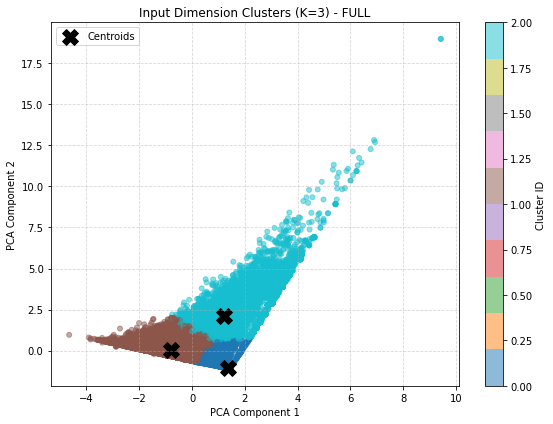


--- INPUT DIMENSION: W1 ---
Silhouette: 0.477 | Davies-Bouldin: 1.112 | Calinski-Harabasz: 56326.8

Average Raw Event Counts per Cluster (for Manual Labeling):
         event_video  event_access  event_wiki  event_discussion
cluster                                                         
0               0.10          0.89        0.03              0.13
1               5.39         19.57        0.35              1.75
2               3.40         16.97        2.62             16.25


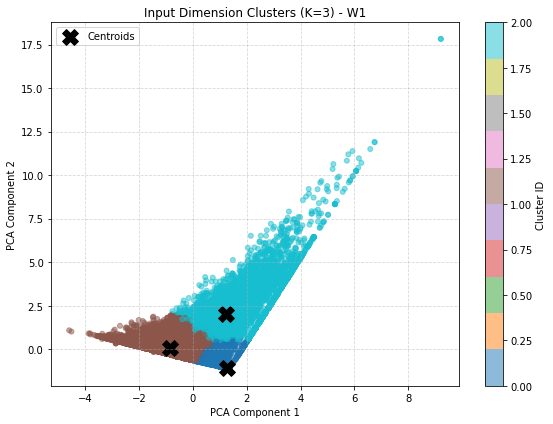


--- INPUT DIMENSION: LAST ---
Silhouette: 0.477 | Davies-Bouldin: 1.118 | Calinski-Harabasz: 53455.0

Average Raw Event Counts per Cluster (for Manual Labeling):
         event_video  event_access  event_wiki  event_discussion
cluster                                                         
0               5.07         18.43        0.21              1.22
1               0.10          0.99        0.02              0.11
2               2.56         12.31        2.05             11.50


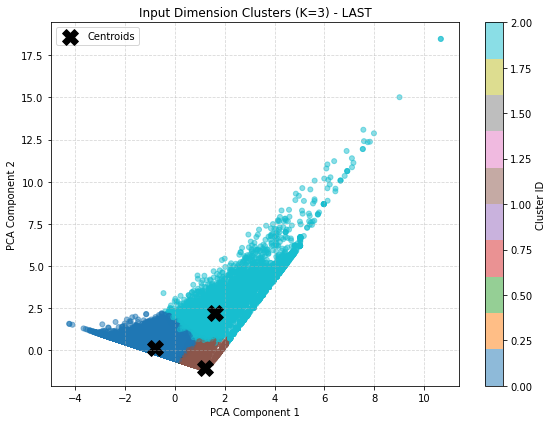

In [10]:
# =====================================================================
# CELL 1 — K-Means (K=3), Input Dimension
# Computes raw_counts_by_slice ONCE here; reused by Cells 2-4 below
# instead of being recomputed. Cluster labels are also stored in
# km_labels_by_slice for reuse. No change to data, random states, or
# algorithm — only removing repeated computation.
# =====================================================================
import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Executing acceleration on: {device}")

input_cols = ['event_video', 'event_access', 'event_wiki', 'event_discussion']
slices = ['full', 'w1', 'last']

REPRESENTATION = "proportional"

if REPRESENTATION == "raw":
    FEATURE_DIR = MODEL_ARTIFACT_ROOT / "temporal_event_counts"
elif REPRESENTATION == "proportional":
    FEATURE_DIR = MODEL_ARTIFACT_ROOT / "temporal_event_proportions"
else:
    raise ValueError("REPRESENTATION must be 'raw' or 'proportional'")

log_train = pd.read_csv(DATA_ROOT / "train/train/log_train.csv")
log_train['time'] = pd.to_datetime(log_train['time'])
log_train = log_train.sort_values(['enrollment_id', 'time'])

first_time = log_train.groupby('enrollment_id')['time'].transform('min')
last_time = log_train.groupby('enrollment_id')['time'].transform('max')

w1_mask = (log_train['time'] - first_time).dt.total_seconds() <= 7 * 24 * 3600
last_mask = (last_time - log_train['time']).dt.total_seconds() <= 7 * 24 * 3600

slice_dataframes = {
    'full': log_train,
    'w1': log_train[w1_mask],
    'last': log_train[last_mask]
}

# --- Compute raw event counts ONCE per slice (this was previously repeated
#     in every downstream cell) ---
raw_counts_by_slice = {}
for slice_name in slices:
    subset_df = slice_dataframes[slice_name]
    raw_counts = subset_df.groupby(['enrollment_id', 'event']).size().unstack(fill_value=0)
    raw_counts.columns = [f'event_{col}' for col in raw_counts.columns]
    raw_counts = raw_counts.reset_index()
    raw_counts_by_slice[slice_name] = raw_counts

km_labels_by_slice = {}

for slice_name in slices:
    norm_path = FEATURE_DIR / f"{slice_name}_norm.csv"
    if not os.path.exists(norm_path):
        continue

    df_norm = pd.read_csv(norm_path)

    cols_to_use = [c for c in input_cols if c in df_norm.columns]
    X_np = df_norm[cols_to_use].values
    # (unused X_tensor GPU copy removed — K-Means runs on X_np via sklearn,
    #  the tensor was never actually consumed)

    kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
    clusters = kmeans.fit_predict(X_np)

    df_norm['cluster'] = clusters
    km_labels_by_slice[slice_name] = clusters  # stored for reuse in Cells 2 & 4

    sil = silhouette_score(X_np, clusters)
    db = davies_bouldin_score(X_np, clusters)
    ch = calinski_harabasz_score(X_np, clusters)

    print(f"\n==================================================")
    print(f"--- INPUT DIMENSION: {slice_name.upper()} ---")
    print(f"==================================================")
    print(f"Silhouette: {sil:.3f} | Davies-Bouldin: {db:.3f} | Calinski-Harabasz: {ch:.1f}")

    raw_counts = raw_counts_by_slice[slice_name]
    merged_raw = df_norm[['enrollment_id', 'cluster']].merge(raw_counts, on='enrollment_id', how='left').fillna(0)
    raw_cols_to_use = [c for c in input_cols if c in merged_raw.columns]
    raw_means = merged_raw.groupby('cluster')[raw_cols_to_use].mean()

    print("\nAverage Raw Event Counts per Cluster (for Manual Labeling):")
    print(raw_means.round(2).to_string())

    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_np)
    df_norm['pca1'] = X_pca[:, 0]
    df_norm['pca2'] = X_pca[:, 1]
    pca_centroids = pca.transform(kmeans.cluster_centers_)

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(df_norm['pca1'], df_norm['pca2'], c=df_norm['cluster'], cmap='tab10', alpha=0.5, s=25)
    plt.scatter(pca_centroids[:, 0], pca_centroids[:, 1], s=250, c='black', marker='X', label='Centroids')
    plt.title(f'Input Dimension Clusters (K=3) - {slice_name.upper()}')
    plt.xlabel('PCA Component 1')
    plt.ylabel('PCA Component 2')
    plt.colorbar(scatter, label='Cluster ID')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()

In [11]:
# =====================================================================
# CELL 2 — Cluster Alignment Analysis, Input Dimension
# Reuses km_labels_by_slice and raw_counts_by_slice from Cell 1 instead
# of refitting K-Means and recomputing raw counts.
# =====================================================================
import numpy as np
import pandas as pd

print("--- Cluster Alignment Analysis ---")

input_cols = ['event_video', 'event_access', 'event_wiki', 'event_discussion']

for slice_name in slices:
    norm_path = FEATURE_DIR / f"{slice_name}_norm.csv"
    df_norm = pd.read_csv(norm_path)
    df_norm['cluster'] = km_labels_by_slice[slice_name]  # reused, not refit

    raw_counts = raw_counts_by_slice[slice_name]  # reused, not recomputed
    merged_raw = df_norm[['enrollment_id', 'cluster']].merge(raw_counts, on='enrollment_id', how='left').fillna(0)

    visual_score = merged_raw.get('event_video', 0) + merged_raw.get('event_access', 0)
    verbal_score = merged_raw.get('event_access', 0) + merged_raw.get('event_wiki', 0) + merged_raw.get('event_discussion', 0)

    df_norm['visual_score'] = visual_score
    df_norm['verbal_score'] = verbal_score

    conditions = [
        df_norm['visual_score'] > df_norm['verbal_score'],
        df_norm['verbal_score'] > df_norm['visual_score']
    ]
    df_norm['true_label'] = np.select(conditions, ['Visual', 'Verbal'], default='Neutral')

    print(f"\n=== {slice_name.upper()} SLICE ===")
    alignment = pd.crosstab(df_norm['cluster'], df_norm['true_label'], normalize='index') * 100
    print(alignment.round(2).to_string())

--- Cluster Alignment Analysis ---

=== FULL SLICE ===
true_label  Neutral  Verbal  Visual
cluster                            
0             94.57    3.27    2.16
1             14.16   10.88   74.96
2              5.10   94.37    0.54

=== W1 SLICE ===
true_label  Neutral  Verbal  Visual
cluster                            
0             94.71    3.42    1.87
1             16.44   10.55   73.01
2              4.53   95.10    0.37

=== LAST SLICE ===
true_label  Neutral  Verbal  Visual
cluster                            
0             19.74    7.63   72.63
1             94.78    3.16    2.06
2              5.73   93.72    0.56


Running DEC on: cuda

--- INPUT DIMENSION: FULL (DEC) ---
    epoch   0 | loss: 0.09002 | label change: 0.0004
    epoch  20 | loss: 0.09134 | label change: 0.0010
    epoch  40 | loss: 0.09116 | label change: 0.0007
    epoch  60 | loss: 0.09058 | label change: 0.0004
    epoch  80 | loss: 0.08985 | label change: 0.0005
Silhouette: 0.472 | Davies-Bouldin: 1.142 | Calinski-Harabasz: 53008.7

Average Raw Event Counts per DEC Cluster (for Manual Labeling):
             event_video  event_access  event_wiki  event_discussion
dec_cluster                                                         
0                   0.16          1.59        0.05              0.15
1                   9.29         33.38        0.49              2.53
2                   7.47         39.51        3.17             27.04


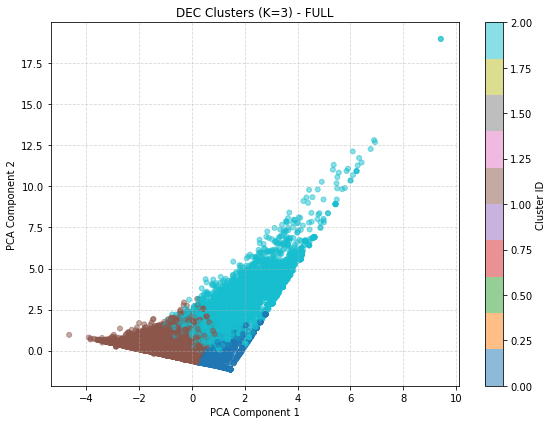


--- INPUT DIMENSION: W1 (DEC) ---
    epoch   0 | loss: 0.09264 | label change: 0.0003
    epoch  20 | loss: 0.09387 | label change: 0.0006
    epoch  40 | loss: 0.09341 | label change: 0.0003
    epoch  60 | loss: 0.09253 | label change: 0.0002
    epoch  80 | loss: 0.09150 | label change: 0.0003
Silhouette: 0.470 | Davies-Bouldin: 1.126 | Calinski-Harabasz: 54369.9

Average Raw Event Counts per DEC Cluster (for Manual Labeling):
             event_video  event_access  event_wiki  event_discussion
dec_cluster                                                         
0                   0.10          1.05        0.05              0.10
1                   5.38         18.86        0.34              1.33
2                   3.82         20.41        2.37             16.46


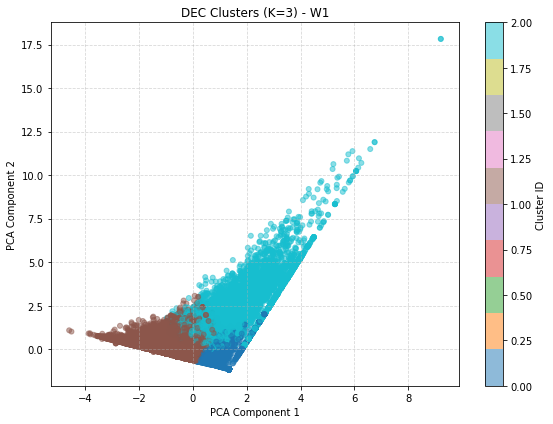


--- INPUT DIMENSION: LAST (DEC) ---
    epoch   0 | loss: 0.08920 | label change: 0.0003
    epoch  20 | loss: 0.09006 | label change: 0.0004
    epoch  40 | loss: 0.08975 | label change: 0.0003
    epoch  60 | loss: 0.08951 | label change: 0.0001
    epoch  80 | loss: 0.08910 | label change: 0.0011
Silhouette: 0.471 | Davies-Bouldin: 1.151 | Calinski-Harabasz: 51891.9

Average Raw Event Counts per DEC Cluster (for Manual Labeling):
             event_video  event_access  event_wiki  event_discussion
dec_cluster                                                         
0                   5.12         18.07        0.20              0.94
1                   0.10          1.23        0.03              0.09
2                   2.89         15.38        1.82             11.59


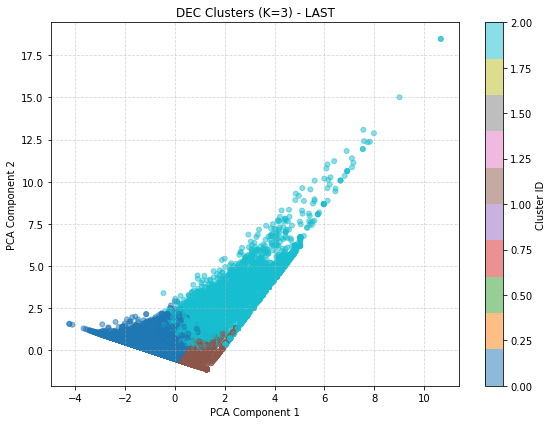

In [12]:
# =====================================================================
# CELL 3 — DEC (Deep Embedded Clustering), Input Dimension
# Reuses raw_counts_by_slice from Cell 1. Stores dec_labels_by_slice
# for reuse in Cell 4 (previously DEC was rerun from scratch there).
# No change to the DEC algorithm, tolerance, or seeding.
# =====================================================================
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score


def target_distribution(q):
    weight = q ** 2 / q.sum(0)
    return (weight.t() / weight.sum(1)).t()


class DECClusteringLayer(nn.Module):
    """Clustering layer only — no encoder. Cluster centers are the
    only learnable parameters, refined directly in the input space."""
    def __init__(self, n_clusters, init_centers, alpha=1.0):
        super().__init__()
        self.alpha = alpha
        self.centers = nn.Parameter(torch.tensor(init_centers, dtype=torch.float32))

    def forward(self, x):
        dist_sq = torch.sum((x.unsqueeze(1) - self.centers.unsqueeze(0)) ** 2, dim=2)
        q = 1.0 / (1.0 + dist_sq / self.alpha)
        q = q ** ((self.alpha + 1.0) / 2.0)
        q = q / torch.sum(q, dim=1, keepdim=True)
        return q


def run_dec(X_np, n_clusters=3, n_epochs=100, lr=0.01, tol=1e-4, device="cpu"):
    kmeans_init = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
    init_pred = kmeans_init.fit_predict(X_np)
    init_centers = kmeans_init.cluster_centers_

    X_tensor = torch.tensor(X_np, dtype=torch.float32, device=device)
    model = DECClusteringLayer(n_clusters, init_centers).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    prev_labels = init_pred
    for epoch in range(n_epochs):
        q = model(X_tensor)
        p = target_distribution(q.detach())

        loss = torch.nn.functional.kl_div(q.log(), p, reduction='batchmean')
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        with torch.no_grad():
            new_labels = torch.argmax(model(X_tensor), dim=1).cpu().numpy()

        changed = np.sum(new_labels != prev_labels) / len(prev_labels)
        if epoch % 20 == 0:
            print(f"    epoch {epoch:>3} | loss: {loss.item():.5f} | label change: {changed:.4f}")
        if changed < tol and epoch > 0:
            print(f"    converged at epoch {epoch} (label change < {tol})")
            break
        prev_labels = new_labels

    with torch.no_grad():
        final_labels = torch.argmax(model(X_tensor), dim=1).cpu().numpy()

    return final_labels


print(f"Running DEC on: {device}\n")

input_cols = ['event_video', 'event_access', 'event_wiki', 'event_discussion']
dec_labels_by_slice = {}

for slice_name in slices:
    norm_path = FEATURE_DIR / f"{slice_name}_norm.csv"
    df_norm = pd.read_csv(norm_path)

    cols_to_use = [c for c in input_cols if c in df_norm.columns]
    X_np = df_norm[cols_to_use].values

    print(f"==================================================")
    print(f"--- INPUT DIMENSION: {slice_name.upper()} (DEC) ---")
    print(f"==================================================")

    torch.manual_seed(42)
    dec_labels = run_dec(X_np, n_clusters=3, device=device)
    df_norm['dec_cluster'] = dec_labels
    dec_labels_by_slice[slice_name] = dec_labels  # stored for reuse in Cell 4

    sil = silhouette_score(X_np, dec_labels)
    db = davies_bouldin_score(X_np, dec_labels)
    ch = calinski_harabasz_score(X_np, dec_labels)
    print(f"Silhouette: {sil:.3f} | Davies-Bouldin: {db:.3f} | Calinski-Harabasz: {ch:.1f}")

    raw_counts = raw_counts_by_slice[slice_name]
    merged_raw = df_norm[['enrollment_id', 'dec_cluster']].merge(raw_counts, on='enrollment_id', how='left').fillna(0)
    raw_cols_to_use = [c for c in input_cols if c in merged_raw.columns]
    raw_means = merged_raw.groupby('dec_cluster')[raw_cols_to_use].mean()

    print("\nAverage Raw Event Counts per DEC Cluster (for Manual Labeling):")
    print(raw_means.round(2).to_string())

    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X_np)

    plt.figure(figsize=(8, 6))
    scatter = plt.scatter(X_pca[:, 0], X_pca[:, 1], c=dec_labels, cmap='tab10', alpha=0.5, s=25)
    plt.title(f'DEC Clusters (K=3) - {slice_name.upper()}')
    plt.xlabel('PCA Component 1')
    plt.ylabel('PCA Component 2')
    plt.colorbar(scatter, label='Cluster ID')
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()
    print()

In [13]:
# =====================================================================
# CELL 4 — Binary Visual-Verbal Scoring -> Cluster-Level Labeling
# Reuses km_labels_by_slice, dec_labels_by_slice, raw_counts_by_slice
# from Cells 1 and 3 — no refitting K-Means, no rerunning DEC.
# =====================================================================
import numpy as np
import pandas as pd

MAJORITY_THRESHOLD = 0.60  # tune this: min. % of a cluster sharing a
                            # binary label before it's called that style
                            # rather than "Intermediate"


def compute_binary_visual_verbal(raw_counts_df):
    """V, R, S per learner from raw event counts. Ties (V == R, including
    V == R == 0) resolve to Verbal, per the spec's tie-break rule."""
    df = raw_counts_df.copy()
    df['V'] = df.get('event_video', 0) + df.get('event_access', 0)
    df['R'] = df.get('event_wiki', 0) + df.get('event_discussion', 0)
    total = df['V'] + df['R']
    df['S'] = np.where(total > 0, (df['V'] - df['R']) / total, 0.0)
    df['binary_label'] = np.where(df['V'] > df['R'], 'Visual', 'Verbal')
    return df


def summarize_cluster_styles(df_with_cluster, cluster_col, majority_threshold=MAJORITY_THRESHOLD):
    summary = df_with_cluster.groupby(cluster_col).agg(
        n_learners=('binary_label', 'size'),
        avg_V=('V', 'mean'),
        avg_R=('R', 'mean'),
        avg_S=('S', 'mean'),
        pct_visual=('binary_label', lambda x: (x == 'Visual').mean() * 100),
        pct_verbal=('binary_label', lambda x: (x == 'Verbal').mean() * 100),
    )

    def assign_style(row):
        if row['pct_visual'] >= majority_threshold * 100:
            return 'Visual'
        elif row['pct_verbal'] >= majority_threshold * 100:
            return 'Verbal'
        return 'Intermediate'

    summary['cluster_style'] = summary.apply(assign_style, axis=1)
    return summary.round(3)


for slice_name in slices:
    print(f"\n{'=' * 60}")
    print(f"--- {slice_name.upper()}: BINARY VISUAL-VERBAL CLUSTER LABELING ---")
    print(f"{'=' * 60}")

    raw_counts = raw_counts_by_slice[slice_name]

    df_km = compute_binary_visual_verbal(raw_counts.assign(cluster=km_labels_by_slice[slice_name]))
    km_summary = summarize_cluster_styles(df_km, 'cluster')
    print("\n[K-Means] Cluster-level Visual/Verbal/Intermediate labeling:")
    print(km_summary.to_string())

    df_dec = compute_binary_visual_verbal(raw_counts.assign(dec_cluster=dec_labels_by_slice[slice_name]))
    dec_summary = summarize_cluster_styles(df_dec, 'dec_cluster')
    print("\n[DEC] Cluster-level Visual/Verbal/Intermediate labeling:")
    print(dec_summary.to_string())


--- FULL: BINARY VISUAL-VERBAL CLUSTER LABELING ---

[K-Means] Cluster-level Visual/Verbal/Intermediate labeling:
         n_learners   avg_V   avg_R  avg_S  pct_visual  pct_verbal cluster_style
cluster                                                                         
0             31490   1.509   0.201  0.091      11.111      88.889        Verbal
1             74855  44.731   4.051  0.909     100.000       0.000        Visual
2             14197  36.154  30.302  0.073      65.859      34.141        Visual

[DEC] Cluster-level Visual/Verbal/Intermediate labeling:
             n_learners   avg_V   avg_R  avg_S  pct_visual  pct_verbal cluster_style
dec_cluster                                                                         
0                 31968   1.751   0.198  0.097      12.059      87.941        Verbal
1                 71432  42.668   3.018  0.924     100.000       0.000        Visual
2                 17142  46.978  30.209  0.165      72.436      27.564        Visu